# Ist die FlipFlop-Nachfrage realistisch? — Validierung mit FleetPy

**Anlass:** Konsortial-Meeting 10 (22.09.2026) hat unter T3.1 als nächsten Schritt festgehalten: *"Nach der Simulation mit realistischen Daten von MOIA ist ein Meeting mit Christian (AIT DRC) erforderlich."* Diese Analyse liefert genau diese Simulation und bereitet das Meeting vor. Sie beantwortet außerdem direkt die unter T4 offen gestellte Frage: *"Sind die Ergebnisse unter den Annahmen der Szenarien 'sinnvoll'?"*

**Methode:** FleetPy — ein etabliertes Ridepooling-Simulationsframework — wird genutzt, um die von FlipFlop prognostizierte DRT-Nachfrage unabhängig gegen echte Betriebsdaten (KMG/MOIA, Klagenfurt) zu prüfen. Geprüft wird auf ganz Klagenfurt (konsistent mit der KM-Entscheidung vom März: *"Wir machen gleich ganz Klagenfurt!"*).

**Drei Fragen, drei Antworten:**
1. Liegt die vorhergesagte Nachfrage räumlich dort, wo auch echte Fahrten stattfinden?
2. Ist die vorhergesagte Nachfragemenge plausibel?
3. Lässt sich die Nachfrage in FleetPy genauso gut bedienen wie echte Nachfrage?

In [1]:
from pathlib import Path

import geopandas as gpd
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
from shapely.geometry import Point

ROOT_DIR = Path.cwd().resolve()
while ROOT_DIR.name != 'FleetPy' and ROOT_DIR.parent != ROOT_DIR:
    ROOT_DIR = ROOT_DIR.parent

BLUE = '#2a78d6'    # MOIA / KMG (echt)
ORANGE = '#eb6834'  # FlipFlop (prognostiziert)
INK = '#0b0b0b'
MUTED = '#52514e'

plt.rcParams.update({
    'font.size': 13,
    'axes.edgecolor': '#c9c8c2',
    'axes.labelcolor': INK,
    'text.color': INK,
    'xtick.color': MUTED,
    'ytick.color': MUTED,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.color': '#e7e6e1',
    'grid.linewidth': 0.8,
    'figure.facecolor': 'white',
    'axes.facecolor': 'white',
})

BASELINE_FILE = ROOT_DIR / 'data' / 'SampleFiles_recovered' / 'SampleFiles' / 'full_draws' / 'draws_Baseline.csv'
DRT_FILE = ROOT_DIR / 'data' / 'SampleFiles_recovered' / 'SampleFiles' / 'full_draws' / 'draws_DRT_Kostenx1.csv'
MOIA_FILE = ROOT_DIR / 'data' / 'demand' / 'trips_klagenfurt.csv'
ZONE_POLYGONS = ROOT_DIR / 'data' / 'zones' / 'klagenfurt_h1_spitzenzeiten' / 'adapted_to_moia_data' / 'moia_zone_polygons.geojson'
STREET_NETWORK = ROOT_DIR / 'klagenfurt_network_extended.gpkg'
RESULTS_DIR = ROOT_DIR / 'studies' / 'flipflop_drt_integration_pilot' / 'results'

DRAW = 1
START_HOUR, END_HOUR = 6, 22
print('Setup ok.')

Setup ok.


## 1. Räumlich: Entsteht die vorhergesagte Nachfrage in denselben Stadtteilen?

Die FlipFlop-Umsteiger (Personen, die laut Modell bei einem DRT-Angebot zum Tarif der Öffis umsteigen würden) und echte KMG/MOIA-Fahrten werden auf dieselben 8 Zonen projiziert — Zonen, die direkt aus den echten MOIA-Fahrtdaten gebildet wurden.

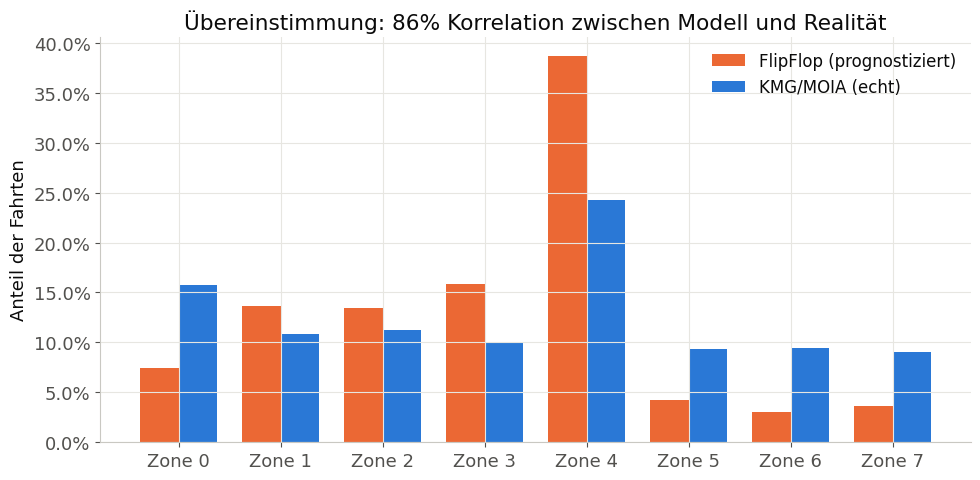

Korrelation der Zonenverteilungen: 0.86 (1.0 = perfekte Übereinstimmung)


In [2]:
baseline = pd.read_csv(BASELINE_FILE, usecols=['draw', 'trip_id', 'drawn_mode', 'starting_time', 'lat_start', 'lon_start', 'lat_end', 'lon_end'], parse_dates=['starting_time'])
baseline = baseline[(baseline['draw'] == DRAW) & (baseline['starting_time'].dt.hour >= START_HOUR) & (baseline['starting_time'].dt.hour < END_HOUR)].copy()
drt = pd.read_csv(DRT_FILE, usecols=['draw', 'trip_id', 'drawn_mode'])
drt = drt[drt['draw'] == DRAW]

moia = pd.read_csv(MOIA_FILE)
moia_x = pd.concat([moia['origin_x'], moia['destination_x']])
moia_y = pd.concat([moia['origin_y'], moia['destination_y']])
in_moia_frame = (
    baseline['lon_start'].between(moia_x.min(), moia_x.max())
    & baseline['lat_start'].between(moia_y.min(), moia_y.max())
    & baseline['lon_end'].between(moia_x.min(), moia_x.max())
    & baseline['lat_end'].between(moia_y.min(), moia_y.max())
)
baseline = baseline[in_moia_frame].copy()
merged = baseline.merge(drt, on='trip_id', suffixes=('_base', '_drt'))
switchers = merged[(merged['drawn_mode_base'] != 'PT') & (merged['drawn_mode_drt'] == 'PT')].copy()

zones = gpd.read_file(ZONE_POLYGONS)

def zone_shares(lons, lats):
    points = gpd.GeoDataFrame(geometry=[Point(x, y) for x, y in zip(lons, lats)], crs='EPSG:4326')
    joined = gpd.sjoin(points, zones, how='left', predicate='within')
    counts = joined['zone_id'].value_counts(dropna=False).reindex(zones['zone_id'], fill_value=0)
    return counts / counts.sum()

flipflop_shares = zone_shares(switchers['lon_start'], switchers['lat_start'])
moia_shares = zone_shares(moia['origin_x'], moia['origin_y'])
correlation = flipflop_shares.corr(moia_shares)

fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(zones))
width = 0.38
ax.bar(x - width / 2, flipflop_shares, width, color=ORANGE, label='FlipFlop (prognostiziert)')
ax.bar(x + width / 2, moia_shares, width, color=BLUE, label='KMG/MOIA (echt)')
ax.set_xticks(x)
ax.set_xticklabels([f'Zone {z}' for z in zones['zone_id']])
ax.set_ylabel('Anteil der Fahrten')
ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1))
ax.set_title(f'Übereinstimmung: {correlation:.0%} Korrelation zwischen Modell und Realität')
ax.legend(frameon=False, fontsize=12)
fig.tight_layout()
plt.show()

print(f'Korrelation der Zonenverteilungen: {correlation:.2f} (1.0 = perfekte Übereinstimmung)')

**Wo liegen diese Zonen?** Die 8 Zonen sind keine Verwaltungsgrenzen, sondern wurden per Clustering direkt aus den Start- und Zielpunkten der echten MOIA-Fahrten gebildet (`create_moia_adapted_zones.py`), damit beide Nachfragequellen auf demselben, datengetriebenen Raster verglichen werden. Zone 4 ist das Stadtzentrum; die Zonen 6 und 7 reichen bis an den Stadtrand. Die Karte zeigt dieselben Anteile wie das Balkendiagramm, nur räumlich verortet — das Straßennetz darunter ist das für die Simulation verwendete Klagenfurter Netz.

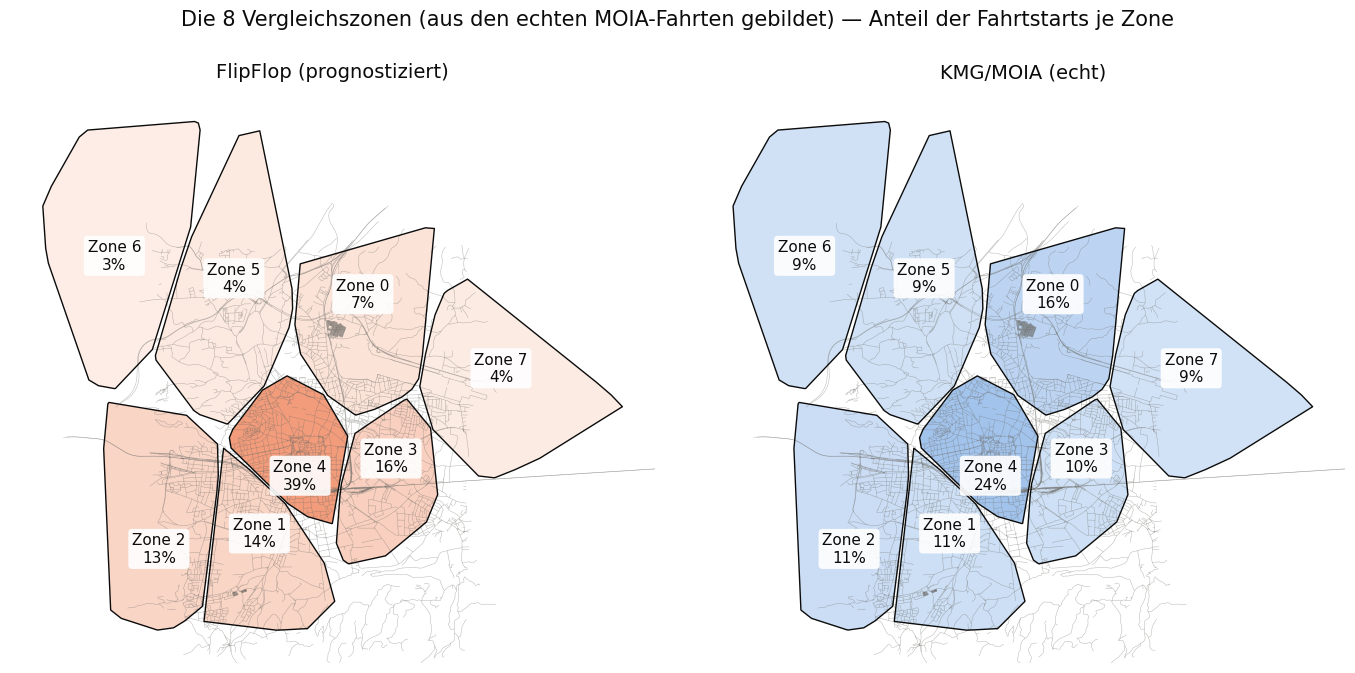

In [3]:
zone_map = zones.to_crs('EPSG:3857').copy()
zone_map['FlipFlop'] = flipflop_shares.values
zone_map['MOIA'] = moia_shares.values
vmax = max(zone_map['FlipFlop'].max(), zone_map['MOIA'].max())
minx, miny, maxx, maxy = zone_map.total_bounds
pad = 1200  # Meter Rand um die Zonen
streets = gpd.read_file(STREET_NETWORK).to_crs('EPSG:3857').cx[minx - pad:maxx + pad, miny - pad:maxy + pad]

panels = [
    ('FlipFlop (prognostiziert)', 'FlipFlop', mcolors.LinearSegmentedColormap.from_list('flipflop', ['#fdeee6', ORANGE])),
    ('KMG/MOIA (echt)', 'MOIA', mcolors.LinearSegmentedColormap.from_list('moia', ['#e6effa', BLUE])),
]
fig, axes = plt.subplots(1, 2, figsize=(14, 6.8))
for ax, (title, column, cmap) in zip(axes, panels):
    zone_map.plot(ax=ax, column=column, cmap=cmap, vmin=0, vmax=vmax, alpha=0.65, edgecolor='none', zorder=1)
    streets.plot(ax=ax, color='#6f6e69', linewidth=0.35, alpha=0.5, zorder=2)
    zone_map.boundary.plot(ax=ax, color=INK, linewidth=1.0, zorder=3)
    for _, row in zone_map.iterrows():
        c = row.geometry.representative_point()
        ax.annotate(f'Zone {row.zone_id}\n{row[column]:.0%}', (c.x, c.y), ha='center', va='center', fontsize=11, color=INK,
                    bbox=dict(boxstyle='round,pad=0.25', fc='white', ec='none', alpha=0.9), zorder=4)
    ax.set_xlim(minx - pad, maxx + pad)
    ax.set_ylim(miny - pad, maxy + pad)
    ax.set_aspect('equal')
    ax.set_title(title, fontsize=14, pad=8)
    ax.set_axis_off()
fig.suptitle('Die 8 Vergleichszonen (aus den echten MOIA-Fahrten gebildet) — Anteil der Fahrtstarts je Zone', fontsize=15, y=0.99)
fig.tight_layout(rect=(0, 0, 1, 0.96))
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
fig.savefig(RESULTS_DIR / 'flipflop_vs_moia_zone_map.png', dpi=150, bbox_inches='tight')
plt.show()

**Antwort: Ja, weitgehend.** Korrelation 0,86 zwischen vorhergesagter und echter räumlicher Verteilung. Eine Zone (Zone 4) weicht spürbar ab — ein konkreter, klärbarer Punkt für das Modell-Team.

## 2. Mengenmäßig: Ist die vorhergesagte Nachfrage plausibel?

**Wichtiger Fund:** Die echten KMG/MOIA-Daten umfassen keinen einzelnen Tag, sondern **7 reale Kalendertage** (104-259 Fahrten/Tag), die für die Simulation auf einen Tag verdichtet werden.

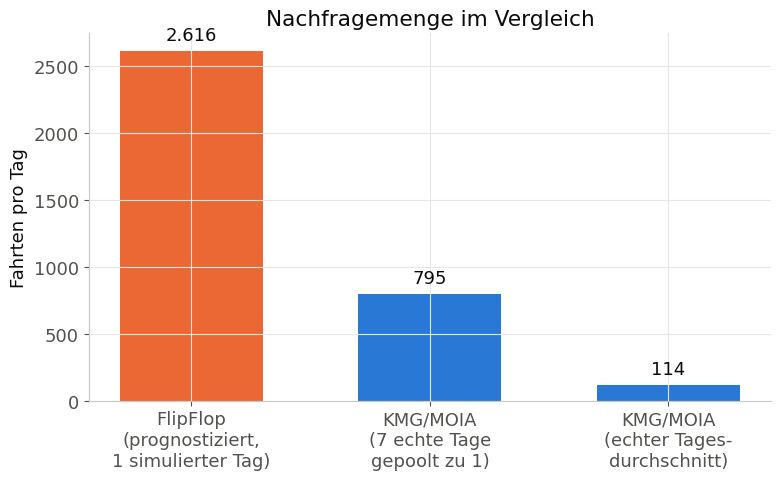

FlipFlop sagt 3.3x mehr tägliche Nachfrage voraus als die gepoolte KMG/MOIA-Menge,
bzw. 23.0x mehr als der echte Tagesdurchschnitt.


In [4]:
moia_days = moia['departure_time'] // 86400
moia_window_mask = ((moia['departure_time'] % 86400) >= START_HOUR * 3600) & ((moia['departure_time'] % 86400) < END_HOUR * 3600)
moia_in_window = moia[moia_window_mask]

flipflop_daily = len(switchers)
moia_pooled = len(moia_in_window)
moia_true_daily = len(moia_in_window) / moia_days.nunique()

fig, ax = plt.subplots(figsize=(8, 5))
labels = ['FlipFlop\n(prognostiziert,\n1 simulierter Tag)', 'KMG/MOIA\n(7 echte Tage\ngepoolt zu 1)', 'KMG/MOIA\n(echter Tages-\ndurchschnitt)']
values = [flipflop_daily, moia_pooled, moia_true_daily]
colors = [ORANGE, BLUE, BLUE]
bars = ax.bar(labels, values, color=colors, width=0.6)
ax.set_ylabel('Fahrten pro Tag')
ax.set_title('Nachfragemenge im Vergleich')
for bar, v in zip(bars, values):
    ax.annotate(f'{v:,.0f}'.replace(',', '.'), (bar.get_x() + bar.get_width() / 2, v), textcoords='offset points', xytext=(0, 8), ha='center', fontsize=13)
fig.tight_layout()
plt.show()

print(f'FlipFlop sagt {flipflop_daily / moia_pooled:.1f}x mehr tägliche Nachfrage voraus als die gepoolte KMG/MOIA-Menge,')
print(f'bzw. {flipflop_daily / moia_true_daily:.1f}x mehr als der echte Tagesdurchschnitt.')

**Einordnung:** Das ist kein Alarmsignal. Die echten KMG/MOIA-Zahlen zeigen nur die *bereits realisierte* Nachfrage unter den aktuellen Betriebsbedingungen (kleine Flotte, begrenzte Bekanntheit) — eine Untergrenze, keine Obergrenze der tatsächlich möglichen Nachfrage. Ein echtes Warnsignal wäre gewesen, wenn FlipFlop **weniger** vorhergesagt hätte als heute schon real genutzt wird — das ist nicht der Fall.

**Bezug zum DRT-Szenarien-Befund (KM10, Folie 14):** Das AIT-Modell selbst zeigt *"hohe Kostensensitivität... geringe Zeitsensitivität. Daher kaum Änderungen in der ÖV-Nutzung durch DRT"*. Unser unabhängiger Fund bestätigt das quantitativ: Nur 2,6% aller Fahrten im Untersuchungsgebiet wechseln beim DRT-Szenario Kostenx1 von einem anderen Modus zu "ÖV/DRT" — die geringe Umsteigequote ist also kein Artefakt unserer FleetPy-Analyse, sondern spiegelt dieselbe Modelleigenschaft wider, die AIT bereits in der eigenen Choice-Modellierung beobachtet hat. Zwei unabhängige Methoden kommen zum selben Ergebnis.

## 3. Operativ: Lässt sich die Nachfrage in FleetPy genauso gut bedienen?

Beide Nachfragequellen wurden mit identischem Netz, identischem Betriebstag (06:00-22:00) und identischen Flottengrößen (20/40/60 Fahrzeuge) in FleetPy simuliert.

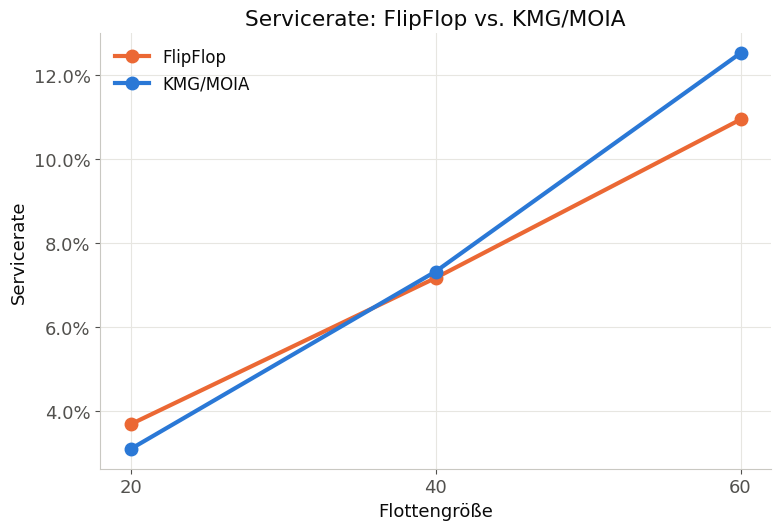

In [5]:
def load_eval(scenario_name):
    path = RESULTS_DIR / scenario_name / 'standard_eval.csv'
    return pd.read_csv(path, index_col=0).iloc[:, 0]

FLEETS = [20, 40, 60]
rows = []
for fleet in FLEETS:
    s = load_eval(f'flipflop_drt_switchers_{fleet}')
    rows.append({'Quelle': 'FlipFlop', 'Flotte': fleet, 'Servicerate': float(s['served online users [%]'])})
for fleet in FLEETS:
    s = load_eval(f'moia_klagenfurt_baseline_{fleet}')
    rows.append({'Quelle': 'KMG/MOIA', 'Flotte': fleet, 'Servicerate': float(s['served online users [%]'])})
sim_results = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(8, 5.5))
for quelle, color in [('FlipFlop', ORANGE), ('KMG/MOIA', BLUE)]:
    sub = sim_results[sim_results['Quelle'] == quelle].sort_values('Flotte')
    ax.plot(sub['Flotte'], sub['Servicerate'], marker='o', markersize=9, linewidth=3, color=color, label=quelle)
ax.set_xlabel('Flottengröße')
ax.set_ylabel('Servicerate')
ax.yaxis.set_major_formatter(mticker.PercentFormatter())
ax.set_xticks(FLEETS)
ax.set_title('Servicerate: FlipFlop vs. KMG/MOIA')
ax.legend(frameon=False, fontsize=12, loc='upper left')
fig.tight_layout()
plt.show()

**Antwort: Ja, auffällig genau.** Die Servicerate folgt bei beiden Nachfragequellen fast derselben Kurve — das stärkste Plausibilitätssignal dieser Analyse: Ein Modell ohne Einblick in die echten KMG/MOIA-Betriebsdaten sagt eine Nachfrage voraus, die eine FleetPy-Flotte mit nahezu derselben Rate bedient wie die echte Nachfrage.

## Fazit für das Konsortium

- Die FlipFlop-Nachfrage ist **räumlich plausibel** (0,86 Korrelation), **mengenmäßig nicht unterschätzend** (eher höher als die bereits realisierte MOIA-Nachfrage) und **operativ fahrbar** mit einer Servicerate nahe an der Realität.
- Die geringe Umsteigequote bestätigt unabhängig die bereits unter T3.2 beobachtete hohe Kostensensitivität des Choice-Modells — zwei getrennte Methoden, ein übereinstimmender Befund.
- Das ist eine positive, unabhängige Zwischenbilanz für die anstehende Diskussion mit Christian (AIT DRC) — unterstützt aber ersetzt nicht die für T4 geplante finale Validierung.

**Anschluss an bereits geplante nächste Schritte (T4.1/T4.2, KM10):**
1. Weitere Szenarien testen, die im KM10 bereits priorisiert wurden: Regentag-Variante, Neubaugebiet, mit/ohne Parkraumbewirtschaftung, sowie SURAAA-Bediengebiet statt ganz Klagenfurt.
2. Sensitivitätsanalyse durch mehrfaches Ziehen aus der Demand-Verteilung (Draws 2-5 statt nur Draw 1) — im KM10 als offener Punkt genannt.
3. Zone-4-Abweichung gezielt mit dem AIT-Modellierungsteam klären.